# 03 — Hasil & Analisis (Minggu 3) — data run R4

**Tujuan (Rincian Project, Minggu 3):** membandingkan metode pembanding terbaik dengan baseline Minggu 1; tabel hasil lintas metode dan lintas fold; **uji signifikansi sederhana (paired t-test antar fold)**; visualisasi: **confusion matrix, boxplot skor per kelas, kurva validasi**.

**Sumber data:** (1) repo penulis (fitur & posterior rilisan → baseline, E1, E2), (2) logit E5 per fold dari run **R4** (`R4/e5/*.npz`), (3) riwayat latih E5 (`R4/history_E5_R4.csv`), (4) skor per fold E3/E3b/E4 yang dibaca dari output notebook R4 (`R4/r4_reported_perfold.csv`; hanya akurasi per fold, dibulatkan 0,1). (5) **opsional:** run E5 tambahan (seed berbeda) dari notebook `02c_E5_run_tambahan.ipynb` untuk **ensemble** (bagian 1b); bila tidak ada, bagian itu dilewati. Data R4 tertanam di notebook ini, jadi cukup repo penulis (dataset/`git clone`) yang perlu tersedia.

**Aturan statistik yang dipakai:** n = 5 fold → daya uji sangat rendah. Selain p-value dilaporkan selisih rata-rata, **CI 95 % selisih (t, df=4)**, ukuran efek (Cohen dz), dan jumlah fold yang lebih baik. **Koreksi Holm** diterapkan pada seluruh perbandingan yang direncanakan. Selisih kecil bukan bukti; selisih antar-run E5 saja ≈ 1 poin.

In [1]:
%%writefile rav_utils.py
"""Utilitas bersama untuk 01_replikasi.ipynb dan 02_pembanding.ipynb.

Semua evaluasi memakai protokol paper (Luna-Jimenez et al., 2022):
subject-wise 5-fold CV dengan pembagian aktor tetap (FOLDS).
"""
import json, os, platform, random, sys
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.preprocessing import MinMaxScaler, StandardScaler

SEED = 2020  # sama dengan seed di repo penulis
FOLDS = {0: [2, 5, 14, 15, 16], 1: [3, 6, 7, 13, 18], 2: [10, 11, 12, 19, 20],
         3: [8, 17, 21, 23, 24], 4: [1, 4, 9, 22]}
EMOTIONS = ["neutral", "calm", "happy", "sad", "angry", "fearful", "disgust", "surprised"]
POST_CLS = [f"embs{i}" for i in range(8)]  # nama kolom posterior di repo


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)


def env_log(path, extra=None):
    """Simpan log lingkungan (versi paket, seed, platform) untuk reproduksibilitas."""
    import sklearn, scipy
    info = {"python": sys.version.split()[0], "platform": platform.platform(),
            "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "scipy": scipy.__version__,
            "seed": SEED, "folds": FOLDS}
    if extra:
        info.update(extra)
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w") as f:
        json.dump(info, f, indent=2)
    return info


def find_repo(candidates=("MMEmotionRecognition-main", "../MMEmotionRecognition-main",
                          "MMEmotionRecognition", "../MMEmotionRecognition")):
    if isinstance(candidates, str):
        candidates = (candidates,)
    for c in candidates:
        if os.path.isdir(os.path.join(c, "data", "trainingData")):
            return os.path.abspath(c)
    raise FileNotFoundError("Folder repo tidak ketemu. Ekstrak MMEmotionRecognition-main.zip di "
                            "samping notebook ini, atau set REPO_DIR manual.")


def _add_labels(df, name_col):
    df["actor"] = df[name_col].str.split("-").str[-1].astype(int)
    df["y"] = df[name_col].str.split("-").str[2].astype(int) - 1
    return df


def load_au_avg(repo):
    """1440 video x 35 fitur AU (rata-rata per video; 17 intensitas '_r' + 18 kehadiran '_c')."""
    df = pd.read_csv(os.path.join(repo, "data/trainingData/avg_MLP80_AUs/data_AUs_avg/df_average_AUs_total.csv"), sep=";")
    df = _add_labels(df, "name")
    feat = [c for c in df.columns if c.startswith("AU")]
    return df, feat


def load_audio_emb(repo):
    """1440 video x 512 fitur (rata-rata embedding feature-encoder xlsr-Wav2Vec2.0)."""
    df = pd.read_csv(os.path.join(repo, "data/trainingData/avg_MLP80_Audio/data/avg_embs_512.csv"), sep=";")
    df["y"] = df["emotion"].astype(int)
    feat = [f"embs{i}" for i in range(512)]
    return df, feat


def make_scaler(kind):
    return {"minmax": MinMaxScaler(feature_range=(0, 1)), "standard": StandardScaler(), None: None, "none": None}[kind]


def run_cv(df, feat, make_clf, norm=None):
    """Subject-wise 5-CV. Mengembalikan akurasi & macro-F1 per fold + prediksi gabungan."""
    accs, f1s, yt, yp, fold_of = [], [], [], [], []
    for f, actors in FOLDS.items():
        te = df["actor"].isin(actors).values
        Xtr, Xte = df.loc[~te, feat].values, df.loc[te, feat].values
        sc = make_scaler(norm)
        if sc is not None:
            Xtr = sc.fit_transform(Xtr)
            Xte = sc.transform(Xte)
        clf = make_clf().fit(Xtr, df.loc[~te, "y"].values)
        p = clf.predict(Xte)
        t = df.loc[te, "y"].values
        accs.append(accuracy_score(t, p) * 100)
        f1s.append(f1_score(t, p, average="macro") * 100)
        yt += list(t); yp += list(p); fold_of += [f] * len(t)
    return {"acc": accs, "f1": f1s, "y_true": np.array(yt), "y_pred": np.array(yp), "fold": np.array(fold_of)}


def ci95(accs, n_per_fold=None, n_total=1440):
    """CI 95% binomial pada akurasi rata-rata (cara paper: 1.96*sqrt(p(1-p)/N))."""
    p = np.mean(accs) / 100
    return 1.96 * np.sqrt(p * (1 - p) / n_total) * 100


def _parse_bilstm(df):
    df = df.copy()
    df["name"] = df["tag"].str.replace(".csv", "", regex=False)
    df["y"] = df["name"].str.split("-").str[2].astype(int) - 1
    P = df["posteriors"].str.split("[").str[-1].str.split("]").str[0].str.split(",", expand=True).apply(pd.to_numeric)
    P.columns = [f"bi{i}" for i in range(8)]
    return pd.concat([df[["name", "y"]], P], axis=1).sort_values("name").reset_index(drop=True)


def load_posteriors(repo, fold):
    """Posterior rilisan penulis untuk 3 cabang fusi: wav2vec FT, bi-LSTM+attention, MLP80 (AU rata-rata)."""
    b = os.path.join(repo, "data/posteriors")
    rd = lambda p, sep: pd.read_csv(os.path.join(b, p), sep=sep)
    out = {}
    for split, w_split, v_split, m_split in (("train", "train", "train", "train"), ("test", "test", "val", "test")):
        a = rd(f"wav2Vec/posteriors/20211020_094500/fold{fold}/posteriors_{w_split}.csv", ";").sort_values("name").reset_index(drop=True)
        v = _parse_bilstm(rd(f"AUs_biLSTM_6213/posteriorsv2/RAVDESS_AUs-{v_split}--fold_{fold + 1}_outof_5.csv", "\t"))
        m = rd(f"avg_MLP80_AUs/posteriors/{m_split}_fold{fold}.csv", ";").sort_values("video_name").reset_index(drop=True)
        assert (a["name"].values == v["name"].values).all() and (v["name"].values == m["video_name"].values).all()
        out[split] = {"name": v["name"].values, "y": v["y"].values,
                      "audio": a[POST_CLS].values, "bilstm": v[[f"bi{i}" for i in range(8)]].values,
                      "mlp": m[POST_CLS].values}
    return out


def per_class_pr(y_true_list, y_pred_list):
    """Precision & recall per kelas, dirata-rata antar fold (seperti Tabel 3 paper)."""
    from sklearn.metrics import precision_recall_fscore_support
    P, R = [], []
    for t, p in zip(y_true_list, y_pred_list):
        pr, rc, _, _ = precision_recall_fscore_support(t, p, labels=range(8), zero_division=0)
        P.append(pr); R.append(rc)
    return np.mean(P, 0) * 100, np.mean(R, 0) * 100


def append_results(path, rows):
    """Tambah baris hasil (format long: eksperimen, fold, metrik) untuk uji signifikansi di Minggu 3."""
    new = pd.DataFrame(rows)
    if os.path.exists(path):
        old = pd.read_csv(path)
        old = old[~old["experiment"].isin(new["experiment"].unique())]
        new = pd.concat([old, new], ignore_index=True)
    new.to_csv(path, index=False)
    return new


def fusion_cv(repo, branches=("audio", "bilstm", "mlp"), make_clf=None, norm="minmax", modify=None):
    """Late fusion ala paper: gabungkan posterior tiap cabang -> normalisasi -> pengklasifikasi (default LogReg C=1).

    modify(fold, d): fungsi opsional untuk mengganti/menambah cabang (d = hasil load_posteriors) -> dipakai di Minggu 2.
    """
    from sklearn.linear_model import LogisticRegression
    from sklearn.utils import shuffle
    if make_clf is None:
        make_clf = lambda: LogisticRegression(C=1.0, max_iter=10000, random_state=SEED)
    accs, f1s, yt, yp, fo = [], [], [], [], []
    for f in range(5):
        d = load_posteriors(repo, f)
        if modify is not None:
            modify(f, d)
        Xtr = np.hstack([d["train"][b] for b in branches]); Xte = np.hstack([d["test"][b] for b in branches])
        ytr, yte = d["train"]["y"], d["test"]["y"]
        Xtr, ytr = shuffle(Xtr, ytr, random_state=SEED)
        sc = make_scaler(norm)
        if sc is not None:
            Xtr = sc.fit_transform(Xtr); Xte = sc.transform(Xte)
        p = make_clf().fit(Xtr, ytr).predict(Xte)
        accs.append(accuracy_score(yte, p) * 100); f1s.append(f1_score(yte, p, average="macro") * 100)
        yt.append(yte); yp.append(p); fo.append(np.full(len(yte), f))
    return {"acc": accs, "f1": f1s, "y_true": np.concatenate(yt), "y_pred": np.concatenate(yp),
            "fold": np.concatenate(fo), "yt_list": yt, "yp_list": yp}


def make_oof_branch(repo, make_clf, tag="au_oof", norm="minmax"):
    """Buat cabang AU baru untuk fusi dengan posterior *out-of-fold* (GroupKFold per aktor di dalam data train).

    Berbeda dari baseline (posterior train in-sample), cara ini menghindari bias optimistik pada pelatih fusi.
    Mengembalikan fungsi `modify(fold, d)` untuk fusion_cv(..., modify=...).
    """
    from sklearn.model_selection import GroupKFold
    au, feat = load_au_avg(repo)
    au = au.set_index("name")

    def modify(fold, d):
        trn, ten = d["train"]["name"], d["test"]["name"]
        Xtr, ytr, g = au.loc[trn, feat].values, au.loc[trn, "y"].values, au.loc[trn, "actor"].values
        Xte = au.loc[ten, feat].values
        sc = make_scaler(norm)
        if sc is not None:
            Xtr = sc.fit_transform(Xtr); Xte = sc.transform(Xte)
        oof = np.zeros((len(Xtr), 8))
        for a, b in GroupKFold(4).split(Xtr, ytr, g):
            oof[b] = make_clf().fit(Xtr[a], ytr[a]).predict_proba(Xtr[b])
        d["train"][tag] = oof
        d["test"][tag] = make_clf().fit(Xtr, ytr).predict_proba(Xte)
    return modify


def run_cv_grid(df, feat, estimator, param_grid, inner_splits=4, n_jobs=-1):
    """CV luar = fold paper (subject-wise). Hiper-parameter dipilih lewat CV DALAM per-aktor pada data latih saja
    (GroupKFold), jadi fold uji tidak dipakai untuk memilih apa pun. Mengembalikan format seperti run_cv + best_params."""
    from sklearn.model_selection import GridSearchCV, GroupKFold
    accs, f1s, yt, yp, fo, best = [], [], [], [], [], []
    for f, actors in FOLDS.items():
        te = df["actor"].isin(actors).values
        Xtr, ytr, g = df.loc[~te, feat].values, df.loc[~te, "y"].values, df.loc[~te, "actor"].values
        Xte, yte = df.loc[te, feat].values, df.loc[te, "y"].values
        gs = GridSearchCV(estimator, param_grid, cv=GroupKFold(inner_splits), scoring="accuracy", n_jobs=n_jobs, refit=True)
        gs.fit(Xtr, ytr, groups=g)
        p = gs.predict(Xte)
        accs.append(accuracy_score(yte, p) * 100); f1s.append(f1_score(yte, p, average="macro") * 100)
        yt += list(yte); yp += list(p); fo += [f] * len(yte); best.append(gs.best_params_)
    return {"acc": accs, "f1": f1s, "y_true": np.array(yt), "y_pred": np.array(yp), "fold": np.array(fo), "best_params": best}

Writing rav_utils.py


In [2]:
%%writefile kaggle_data.py
"""Deteksi otomatis SEMUA data yang tersedia (Kaggle /kaggle/input atau folder lokal).

Tidak mengasumsikan struktur folder. Fungsi `prepare()`:
  1. memindai semua file di semua dataset yang terpasang,
  2. mengekstrak zip yang belum terekstrak (kecuali zip video besar, tidak dibutuhkan E1-E3),
  3. mencari repo MMEmotionRecognition (folder yang punya data/trainingData/...),
     dan jika tidak ada -> git clone otomatis (butuh Internet ON di Kaggle),
  4. mengindeks semua file RAVDESS bernama baku (audio/video, speech/song),
  5. menyiapkan tabel 1.440 rekaman speech untuk E3.
"""
import os, re, subprocess, zipfile
import pandas as pd

RAV = re.compile(r"^(\d\d)-(\d\d)-(\d\d)-(\d\d)-(\d\d)-(\d\d)-(\d\d)\.(wav|mp4)$", re.I)
MARKER = os.path.join("data", "trainingData", "avg_MLP80_AUs", "data_AUs_avg", "df_average_AUs_total.csv")
REPO_URL = "https://github.com/cristinalunaj/MMEmotionRecognition"


def roots():
    if os.environ.get("RAV_INPUT"):
        return [os.environ["RAV_INPUT"]]
    return ["/kaggle/input"] if os.path.isdir("/kaggle/input") else ["."]


def working_dir():
    if os.environ.get("RAV_WORK"):
        return os.environ["RAV_WORK"]
    return "/kaggle/working" if os.path.isdir("/kaggle/working") else "."


def list_files(root_dirs):
    out = []
    for r in root_dirs:
        for dp, _, fns in os.walk(r):
            if "/.git" in dp.replace("\\", "/"):
                continue
            out += [os.path.join(dp, f) for f in fns]
    return out


def _top(path, root_dirs):
    for r in root_dirs:
        if path.startswith(r):
            rel = os.path.relpath(path, r).split(os.sep)
            return rel[0]
    return "?"


def inventory(files, root_dirs):
    if not files:
        return pd.DataFrame(columns=["dataset/folder", "ext", "jumlah_file"])
    df = pd.DataFrame({"path": files})
    df["dataset/folder"] = df["path"].map(lambda p: _top(p, root_dirs))
    df["ext"] = df["path"].str.extract(r"(\.[A-Za-z0-9]+)$")[0].str.lower().fillna("(none)")
    return df.groupby(["dataset/folder", "ext"]).size().rename("jumlah_file").reset_index()


def extract_zips(files, dest, skip_words=("video",), max_gb=6.0):
    done = []
    for z in [f for f in files if f.lower().endswith(".zip")]:
        base = os.path.basename(z)
        if any(w in base.lower() for w in skip_words):
            print(f"  [lewati zip video] {base} (tidak dibutuhkan untuk E1-E3)")
            continue
        if os.path.getsize(z) > max_gb * 1e9:
            print(f"  [lewati zip >{max_gb} GB] {base}")
            continue
        out = os.path.join(dest, os.path.splitext(base)[0])
        if not os.path.isdir(out):
            print(f"  ekstrak {base} -> {out}")
            os.makedirs(out, exist_ok=True)
            with zipfile.ZipFile(z) as zf:
                zf.extractall(out)
        done.append(out)
    return done


def find_repo(files):
    suf = MARKER.replace("\\", "/")
    for f in files:
        p = f.replace("\\", "/")
        if p.endswith(suf):
            return os.path.abspath(p[: -len(suf)].rstrip("/"))
    return None


def clone_repo(dest):
    target = os.path.join(dest, "MMEmotionRecognition")
    if not os.path.isdir(target):
        print("  repo tidak ada di dataset -> git clone ...")
        try:
            subprocess.run(["git", "clone", "--depth", "1", "-q", REPO_URL, target], check=True, timeout=600)
        except Exception as e:
            print("  git clone gagal:", e, "\n  (di Kaggle: aktifkan Internet di Settings, atau tambahkan repo sebagai dataset)")
            return None
    return target if os.path.exists(os.path.join(target, MARKER)) else None


def index_ravdess(files):
    rows = []
    for f in files:
        m = RAV.match(os.path.basename(f))
        if m:
            g = list(map(int, m.groups()[:7]))
            rows.append([f, m.group(8).lower()] + g)
    cols = ["path", "ext", "modality", "vocal", "emotion", "intensity", "statement", "repetition", "actor"]
    return pd.DataFrame(rows, columns=cols)


def prepare(extract=True, allow_git=True):
    rd = roots(); work = working_dir()
    print("Root data :", rd, "| working:", work)
    files = list_files(rd)
    print(f"Total file terdeteksi: {len(files)}")
    if not files:
        for r in rd:
            print(f"  isi {r}:", os.listdir(r) if os.path.isdir(r) else "(folder tidak ada)")
        print("  PERINGATAN: tidak ada dataset terpasang. Di Kaggle: panel kanan -> Input -> Add Input -> pilih dataset,\n"
              "  lalu jalankan ulang. Tanpa dataset, hanya repo (git clone) yang bisa dipakai -> E1/E2 jalan, E3 dilewati.")
    inv = inventory(files, rd)
    if extract:
        ex = extract_zips(files, os.path.join(work, "extracted"))
        if ex:
            files += list_files(ex)
    repo = find_repo(files)
    if repo is None and allow_git:
        repo = clone_repo(work)
        if repo:
            files += list_files([repo])
    rav = index_ravdess(files)
    aud = rav[rav.ext == "wav"]
    def _mk(df):
        df = df.copy()
        if len(df):
            df["name"] = ["01-" + "-".join(f"{int(v):02d}" for v in row)
                          for row in df[["vocal", "emotion", "intensity", "statement", "repetition", "actor"]].values]
            return df.drop_duplicates("name").sort_values("name").reset_index(drop=True)
        df["name"] = pd.Series(dtype=str)
        return df
    speech = _mk(aud[aud.vocal == 1])
    song = _mk(aud[aud.vocal == 2])          # tersedia untuk pilihan CHANNEL="song"; BUKAN bagian protokol paper
    if repo and len(speech):  # speech dibatasi ke 1.440 rekaman protokol paper
        want = set(pd.read_csv(os.path.join(repo, "data/ravdess_videos.csv"), header=None)[0].astype(str).str.strip())
        speech = speech[speech.name.isin(want)].reset_index(drop=True)
    summ = {"file_total": len(files), "repo": repo, "wav_total": len(aud), "wav_speech_dipakai": len(speech),
            "wav_song(tersedia; default tidak dipakai)": len(song), "aktor_song": int(song.actor.nunique()) if len(song) else 0,
            "emosi_song": sorted(song.emotion.unique().tolist()) if len(song) else [], "video_mp4": int((rav.ext == "mp4").sum())}
    print("\nRingkasan:", summ)
    return {"root": rd, "work": work, "inventory": inv, "repo": repo, "ravdess_index": rav,
            "audio_speech": speech if len(speech) else None, "audio_song": song if len(song) else None, "summary": summ}

Writing kaggle_data.py


In [3]:
%%writefile w2v_finetune.py
"""E5: fine-tuning Wav2Vec2 dengan model pra-latih YANG SAMA seperti paper, resep optimasi berbeda.

Yang SAMA dengan paper : checkpoint jonatasgrosman/wav2vec2-large-xlsr-53-english, feature-encoder (CNN) dibekukan,
                         pooling rata-rata + MLP (1024 -> tanh -> 8), subject-wise 5-CV (fold sama), 1.440 rekaman.
Yang BERBEDA (optimasi) : LR terpisah (backbone kecil, head besar) + warmup + cosine decay, label smoothing,
                         rata-rata berbobot semua lapisan transformer, masked mean-pooling, augmentasi derau/potong tepi,
                         gradient clipping, fp16.
Pelaporan: epoch TERAKHIR (bersih) dan epoch terbaik pada fold uji (= cara paper; optimistis, hanya untuk perbandingan).
"""
import os, time, math
import numpy as np
import pandas as pd

SR = 16000
DEFAULT_CFG = dict(
    model_id="jonatasgrosman/wav2vec2-large-xlsr-53-english", pretrained=True, epochs=15, bs=4, accum=2,
    lr_backbone=3e-5, lr_head=1e-3, weight_decay=0.01, warmup_frac=0.1, label_smoothing=0.1,
    layer_weighted=True, head_dropout=0.1, mask_time_prob=0.05, grad_ckpt=False, noise_p=0.5, seed=2020, max_sec=6.0,
)


def load_waveforms(df, max_sec=6.0, n_jobs=-1):
    import librosa
    from joblib import Parallel, delayed
    f = lambda p: librosa.load(p, sr=SR, mono=True)[0][: int(max_sec * SR)].astype(np.float32)
    return Parallel(n_jobs=n_jobs)(delayed(f)(p) for p in df["path"])


def _collate(waves, idx, train, rng, noise_p):
    ws = []
    for i in idx:
        w = waves[i]
        if train:
            a, b = int(rng.integers(0, int(0.15 * SR) + 1)), int(rng.integers(0, int(0.15 * SR) + 1))
            if len(w) > a + b + SR:
                w = w[a: len(w) - b]
            if rng.random() < noise_p:
                snr = rng.uniform(15, 35)
                w = w + rng.standard_normal(len(w)).astype(np.float32) * np.sqrt((w.var() + 1e-8) / 10 ** (snr / 10))
        ws.append(((w - w.mean()) / np.sqrt(w.var() + 1e-7)).astype(np.float32))
    L = max(len(w) for w in ws)
    x = np.zeros((len(ws), L), np.float32); m = np.zeros((len(ws), L), np.int64)
    for k, w in enumerate(ws):
        x[k, : len(w)] = w; m[k, : len(w)] = 1
    import torch
    return torch.from_numpy(x), torch.from_numpy(m)


def build_model(cfg, n_classes=8, config=None):
    import torch, torch.nn as nn
    from transformers import Wav2Vec2Model

    class W2VClassifier(nn.Module):
        def __init__(self):
            super().__init__()
            if config is not None:                     # dipakai untuk uji mekanisme (model acak kecil)
                self.w2v = Wav2Vec2Model(config)
            else:
                self.w2v = Wav2Vec2Model.from_pretrained(cfg["model_id"], layerdrop=0.0, mask_time_prob=cfg["mask_time_prob"])
            self.w2v.feature_extractor._freeze_parameters()      # CNN beku seperti paper
            if cfg["grad_ckpt"]:
                self.w2v.gradient_checkpointing_enable()
            H, nl = self.w2v.config.hidden_size, self.w2v.config.num_hidden_layers + 1
            self.use_mask = getattr(self.w2v.config, "feat_extract_norm", "layer") == "layer"
            self.layer_w = nn.Parameter(torch.zeros(nl)) if cfg["layer_weighted"] else None
            self.drop = nn.Dropout(cfg["head_dropout"]); self.dense = nn.Linear(H, H); self.out = nn.Linear(H, n_classes)

        def forward(self, x, mask):
            o = self.w2v(x, attention_mask=mask if self.use_mask else None, output_hidden_states=self.layer_w is not None)
            if self.layer_w is not None:
                hs = torch.stack(o.hidden_states, 0)
                h = (torch.softmax(self.layer_w, 0)[:, None, None, None].to(hs.dtype) * hs).sum(0)
            else:
                h = o.last_hidden_state
            if self.use_mask:
                fm = self.w2v._get_feature_vector_attention_mask(h.shape[1], mask).to(h.dtype)
                pooled = (h * fm[..., None]).sum(1) / fm.sum(1, keepdim=True).clamp(min=1)
            else:
                pooled = h.mean(1)
            return self.out(self.drop(torch.tanh(self.dense(self.drop(pooled)))))
    return W2VClassifier()


def _predict(model, waves, idx, device, bs=8):
    import torch
    model.eval(); outs = []
    order = sorted(idx, key=lambda i: len(waves[i]))
    with torch.no_grad():
        for i in range(0, len(order), bs):
            x, m = _collate(waves, order[i:i + bs], False, None, 0)
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=(device == "cuda")):
                outs.append(model(x.to(device), m.to(device)).float().cpu())
    import torch as T
    lg = T.cat(outs).numpy(); inv = np.empty(len(order), int); inv[np.argsort(order)] = np.arange(len(order))
    pos = {j: k for k, j in enumerate(order)}
    return lg[[pos[i] for i in idx]]


def run_fold(fold, waves, names, y, actors, folds, cfg, device, out_dir="results/e5", model_config=None, log=print):
    import torch, torch.nn as nn
    os.makedirs(out_dir, exist_ok=True)
    path = os.path.join(out_dir, f"e5_fold{fold}.npz")
    if os.path.exists(path):
        log(f"fold {fold}: sudah ada ({path}) -> dilewati"); return
    te = np.isin(actors, folds[fold]); tri, tei = np.where(~te)[0], np.where(te)[0]
    torch.manual_seed(cfg["seed"] + fold); rng = np.random.default_rng(cfg["seed"] + fold)
    model = build_model(cfg, config=model_config).to(device)
    head = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith("w2v.")]
    back = [p for n, p in model.named_parameters() if p.requires_grad and n.startswith("w2v.")]
    opt = torch.optim.AdamW([{"params": back, "lr": cfg["lr_backbone"]}, {"params": head, "lr": cfg["lr_head"]}], weight_decay=cfg["weight_decay"])
    steps = math.ceil(len(tri) / (cfg["bs"] * cfg["accum"])) * cfg["epochs"]; warm = max(1, int(cfg["warmup_frac"] * steps))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, steps - warm))))
    scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))
    crit = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"]); yt = torch.from_numpy(y).long()
    hist = []
    for ep in range(1, cfg["epochs"] + 1):
        model.train(); t0 = time.time(); perm = rng.permutation(tri); tl, pend = 0.0, 0
        for i in range(0, len(perm), cfg["bs"]):
            bi = perm[i:i + cfg["bs"]]; x, m = _collate(waves, bi, True, rng, cfg["noise_p"])
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=(device == "cuda")):
                loss = crit(model(x.to(device), m.to(device)).float(), yt[bi].to(device))
            scaler.scale(loss / cfg["accum"]).backward(); tl += loss.item() * len(bi); pend += 1
            if pend == cfg["accum"]:
                scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step(); pend = 0
        if pend:
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
        lg = _predict(model, waves, tei, device)
        vl = nn.functional.cross_entropy(torch.from_numpy(lg), yt[tei]).item(); va = float((lg.argmax(1) == y[tei]).mean() * 100)
        hist.append((ep, tl / len(tri), vl, va))
        log(f"fold {fold} ep {ep:>2}/{cfg['epochs']} train_loss {tl/len(tri):.3f} | test_loss {vl:.3f} test_acc {va:.1f} | {time.time()-t0:.0f}s")
    lg_te = lg; lg_tr = _predict(model, waves, tri, device)       # logit epoch TERAKHIR (bersih)
    h = np.array(hist)
    np.savez_compressed(path, names_train=names[tri], logits_train=lg_tr, names_test=names[tei], logits_test=lg_te,
                        y_test=y[tei], hist=h, last_acc=h[-1, 3], best_acc=h[:, 3].max(), best_epoch=int(h[h[:, 3].argmax(), 0]))
    del model, opt; 
    if device == "cuda":
        torch.cuda.empty_cache()


def make_audio_modify(out_dir="results/e5", tag="audio_e5"):
    """Pengganti cabang audio paper pada fusion_cv: logit E5 diselaraskan berdasarkan nama rekaman."""
    def modify(fold, d):
        z = np.load(os.path.join(out_dir, f"e5_fold{fold}.npz"), allow_pickle=True)
        for split in ("train", "test"):
            pos = {n: i for i, n in enumerate(z[f"names_{split}"])}
            d[split][tag] = z[f"logits_{split}"][[pos[n] for n in d[split]["name"]]]
    return modify


def summarize(out_dir="results/e5"):
    rows = []
    for f in range(5):
        z = np.load(os.path.join(out_dir, f"e5_fold{f}.npz"), allow_pickle=True)
        rows.append({"fold": f, "acc_last": float(z["last_acc"]), "acc_best_on_test(cara paper)": float(z["best_acc"]), "best_epoch": int(z["best_epoch"])})
    return pd.DataFrame(rows)

Writing w2v_finetune.py


## 0. Setup & data R4

In [4]:
R4_B64 = "..."

In [5]:
import os, io, zipfile, base64, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
warnings.filterwarnings("ignore")
import kaggle_data as kd, rav_utils as u, w2v_finetune as wf

PREP = kd.prepare(extract=False)                       # cari repo penulis (atau git clone)
REPO_DIR = PREP["repo"]; assert REPO_DIR, "Repo penulis tidak ditemukan: tambahkan sebagai dataset atau aktifkan Internet."
os.makedirs("results", exist_ok=True)
if not os.path.isdir("R4"):                            # ekstrak data R4 yang tertanam
    zipfile.ZipFile(io.BytesIO(base64.b64decode(R4_B64))).extractall(".")
E5_DIR, HIST, REPORTED = "R4/e5", "R4/history_E5_R4.csv", "R4/r4_reported_perfold.csv"
print("Repo:", REPO_DIR, "| E5:", sorted(os.listdir(E5_DIR)))
CLASSES = ["Neutral", "Calm", "Happy", "Sad", "Angry", "Fearful", "Disgusted", "Surprised"]

Root data : ['/kaggle/input'] | working: /kaggle/working
Total file terdeteksi: 7381
  repo tidak ada di dataset -> git clone ...

Ringkasan: {'file_total': 7568, 'repo': '/kaggle/working/MMEmotionRecognition', 'wav_total': 2452, 'wav_speech_dipakai': 1440, 'wav_song(tersedia; default tidak dipakai)': 1012, 'aktor_song': 23, 'emosi_song': [1, 2, 3, 4, 5, 6], 'video_mp4': 4904}
Repo: /kaggle/working/MMEmotionRecognition | E5: ['e5_fold0.npz', 'e5_fold1.npz', 'e5_fold2.npz', 'e5_fold3.npz', 'e5_fold4.npz']


## 1. Skor per fold semua metode
Prediksi dihitung ulang dari data yang ada (bukan disalin), lalu **dicocokkan dengan angka yang tercatat di notebook R4** sebagai pemeriksaan. Posterior paper memakai urutan kelas internal sendiri, sehingga kolomnya dipetakan ke label dengan algoritma Hungarian **hanya pada data latih** (tanpa melihat data uji).

In [6]:
def align_map(A, ytr):
    C_ = np.zeros((8, 8))
    for k in range(8):
        for c in range(8):
            C_[k, c] = ((A.argmax(1) == k) & (ytr == c)).sum()
    r, c = linear_sum_assignment(-C_); return dict(zip(r, c))

def to_lists(r):                                       # hasil run_cv / fusion_cv -> daftar per fold
    if "yt_list" in r: return r["yt_list"], r["yp_list"]
    return ([r["y_true"][r["fold"] == f] for f in range(5)], [r["y_pred"][r["fold"] == f] for f in range(5)])

S = {}                                                 # nama -> {acc, f1, rec, yt, yp, n, family, source}
def add(name, yt, yp, family, source="dihitung ulang", n=1440):
    S[name] = dict(acc=[accuracy_score(t, p) * 100 for t, p in zip(yt, yp)], f1=[f1_score(t, p, average="macro") * 100 for t, p in zip(yt, yp)],
                   rec=np.array([recall_score(t, p, labels=range(8), average=None, zero_division=0) * 100 for t, p in zip(yt, yp)]),
                   yt=yt, yp=yp, n=n, family=family, source=source)

# --- posterior rilisan paper: audio FT-Wav2Vec2 & bi-LSTM ---
tA, pA, tB, pB = [], [], [], []
for f in range(5):
    d = u.load_posteriors(REPO_DIR, f); ytr, yte = d["train"]["y"], d["test"]["y"]
    for b, (lt, lp) in (("audio", (tA, pA)), ("bilstm", (tB, pB))):
        m = align_map(d["train"][b], ytr); lp.append(np.array([m[k] for k in d["test"][b].argmax(1)])); lt.append(yte)
add("Paper audio FT-Wav2Vec2", tA, pA, "audio", "posterior rilisan paper")
add("Paper visual bi-LSTM", tB, pB, "visual", "posterior rilisan paper")

# --- model statis paper (replikasi M1) ---
au, au_f = u.load_au_avg(REPO_DIR); emb, emb_f = u.load_audio_emb(REPO_DIR)
add("Paper audio FE: SVC C=10 (emb 512-d)", *to_lists(u.run_cv(emb, emb_f, lambda: SVC(C=10, random_state=u.SEED), None)), "audio_FE")
add("Paper audio FE: MLP80 (emb 512-d)", *to_lists(u.run_cv(emb, emb_f, lambda: MLPClassifier((80,), random_state=u.SEED), None)), "audio_FE")
add("Paper visual statis: MLP80 (AU rata-rata)", *to_lists(u.run_cv(au, au_f, lambda: MLPClassifier((80,), random_state=u.SEED), "minmax")), "visual")
# --- E1 ---
add("E1: SVC C=1 balanced (AU)", *to_lists(u.run_cv(au, au_f, lambda: SVC(C=1, class_weight="balanced", random_state=u.SEED), "minmax")), "visual")
add("E1: ExtraTrees-500 balanced (AU)", *to_lists(u.run_cv(au, au_f, lambda: ExtraTreesClassifier(500, class_weight="balanced", random_state=u.SEED, n_jobs=-1), None)), "visual")
# --- fusi: baseline & E2 ---
LR = lambda **k: (lambda: LogisticRegression(max_iter=10000, random_state=u.SEED, **k))
add("Fusi baseline (replikasi 86,70)", *to_lists(u.fusion_cv(REPO_DIR)), "fusion")
add("E2a: LogReg balanced", *to_lists(u.fusion_cv(REPO_DIR, make_clf=LR(C=1, class_weight="balanced"))), "fusion")
add("E2a: LogReg C=10", *to_lists(u.fusion_cv(REPO_DIR, make_clf=LR(C=10))), "fusion")
add("E2a: SVC RBF", *to_lists(u.fusion_cv(REPO_DIR, make_clf=lambda: SVC(C=1, random_state=u.SEED))), "fusion")
add("E2a: RandomForest-300", *to_lists(u.fusion_cv(REPO_DIR, make_clf=lambda: RandomForestClassifier(300, random_state=u.SEED, n_jobs=-1))), "fusion")
mod_svc = u.make_oof_branch(REPO_DIR, lambda: SVC(C=1, probability=True, random_state=u.SEED))
add("E2c: + AU out-of-fold (SVC) sbg cabang ke-4", *to_lists(u.fusion_cv(REPO_DIR, branches=("audio", "bilstm", "mlp", "au_oof"), modify=mod_svc)), "fusion")
# --- E5 (run R4) dari logit tersimpan ---
tE, pE = [], []
for f in range(5):
    z = np.load(f"{E5_DIR}/e5_fold{f}.npz", allow_pickle=True); tE.append(z["y_test"]); pE.append(z["logits_test"].argmax(1))
add("E5 audio (epoch terakhir, R4)", tE, pE, "audio", "logit E5 R4")
mod_a = wf.make_audio_modify(E5_DIR)
add("E5 fusi (audio E5 + visual paper)", *to_lists(u.fusion_cv(REPO_DIR, branches=("audio_e5", "bilstm", "mlp"), modify=mod_a)), "fusion", "logit E5 R4")
def mod_both(f, d): mod_a(f, d); mod_svc(f, d)
add("E5 fusi + AU out-of-fold", *to_lists(u.fusion_cv(REPO_DIR, branches=("audio_e5", "bilstm", "mlp", "au_oof"), modify=mod_both)), "fusion", "logit E5 R4")

# --- E3 / E3b / E4: hanya akurasi per fold dari output notebook R4 ---
REP = pd.read_csv(REPORTED).set_index("experiment")
def rep_acc(name): return [float(REP.loc[name, f"fold{i}"]) for i in range(5)]
REPORTED_ONLY = {"E3: MFCC + SVC RBF C=10": ("E3_SVC_RBF_C10", "audio", 1440), "E3: MFCC + RandomForest-500": ("E3_RF500", "audio", 1440),
                 "E3b: fitur kaya + SVC tuning CV-dalam": ("E3b_SVC_rich", "audio", 1440),
                 "E4 [SONG, tidak sebanding]: CNN log-mel": ("E4_CNN_logmel_song", "song_tidak_sebanding", 1012)}
for nm, (key, fam, n) in REPORTED_ONLY.items():
    S[nm] = dict(acc=rep_acc(key), f1=None, f1_mean=float(REP.loc[key, "f1_macro_mean"]), rec=None, yt=None, yp=None, n=n, family=fam, source="dibaca dari output R4")

# --- pemeriksaan silang: hitung-ulang vs angka tercatat di notebook R4 ---
CHECK = {"Paper visual statis: MLP80 (AU rata-rata)": "E1_MLP80", "E1: SVC C=1 balanced (AU)": "E1_SVC_C1_balanced", "E1: ExtraTrees-500 balanced (AU)": "E1_ExtraTrees500_balanced",
         "Fusi baseline (replikasi 86,70)": "E2a_baseline_LR_C1", "E2a: LogReg balanced": "E2a_LR_balanced", "E2a: LogReg C=10": "E2a_LR_C10", "E2a: SVC RBF": "E2a_SVC_RBF",
         "E2a: RandomForest-300": "E2a_RF300", "E2c: + AU out-of-fold (SVC) sbg cabang ke-4": "E2c_SVC_OOF_4th", "E5 audio (epoch terakhir, R4)": "E5_audio_last",
         "E5 fusi (audio E5 + visual paper)": "E5_fusion", "E5 fusi + AU out-of-fold": "E5_fusion_AUoof"}
chk = pd.DataFrame([{"metode": k, "maks |selisih| per fold (poin)": round(float(np.max(np.abs(np.array(S[k]["acc"]) - np.array(rep_acc(v))))), 2)} for k, v in CHECK.items()])
chk["toleransi"] = [0.5 if "RandomForest" in m else 0.101 for m in chk["metode"]]
chk["cocok"] = chk.iloc[:, 1] <= chk["toleransi"]
chk

,metode,maks |selisih| per fold (poin),toleransi,cocok
0,Paper visual statis: MLP80 (AU rata-rata),0.03,0.101,True
1,E1: SVC C=1 balanced (AU),0.05,0.101,True
2,E1: ExtraTrees-500 balanced (AU),0.03,0.101,True
3,"Fusi baseline (replikasi 86,70)",0.03,0.101,True
4,E2a: LogReg balanced,0.03,0.101,True
5,E2a: LogReg C=10,0.03,0.101,True
6,E2a: SVC RBF,0.05,0.101,True
7,E2a: RandomForest-300,0.05,0.500,True
8,E2c: + AU out-of-fold (SVC) sbg cabang ke-4,0.03,0.101,True
9,"E5 audio (epoch terakhir, R4)",0.03,0.101,True


In [7]:
print("Paper audio (posterior): rata-rata %.2f (paper: 81,82) | Paper bi-LSTM (posterior): %.2f (paper: 62,13)" % (np.mean(S["Paper audio FT-Wav2Vec2"]["acc"]), np.mean(S["Paper visual bi-LSTM"]["acc"])))
bad = chk[~chk["cocok"]]
if len(bad): print("PERHATIAN: ada metode yang tidak cocok dengan angka tercatat -> periksa versi pustaka/seed:\n", bad.to_string())
else: print("Semua hitung-ulang cocok dengan angka di notebook R4 (<= 0,1 poin per fold; RandomForest <= 0,5 karena bergantung versi scikit-learn).")

Paper audio (posterior): rata-rata 81.82 (paper: 81,82) | Paper bi-LSTM (posterior): 62.13 (paper: 62,13)
Semua hitung-ulang cocok dengan angka di notebook R4 (<= 0,1 poin per fold; RandomForest <= 0,5 karena bergantung versi scikit-learn).


## 1b. Ensemble E5: rata-rata logit beberapa run (opsional)
**Pertanyaan:** apakah derau antar-run E5 (±0,5 poin audio, ±0,3 poin fusi pada tiga run yang ada) yang menahan fusi E5 di bawah paper? Ensemble merata-ratakan logit run dengan seed berbeda, resep tetap sama.

**Aturan (ditetapkan sebelum melihat hasil):**
- **Semua** run lengkap (5 fold) yang ditemukan dipakai, tanpa memilih run yang bagus. Run R4 selalu masuk.
- Metode tunggal: **rata-rata logit** (train dan uji, selaras per nama rekaman), lalu kepala fusi yang sama (MinMax → LogReg C=1) dengan posterior visual paper.
- Ensemble diuji dengan paired t-test seperti pembanding lain, dan masuk koreksi Holm (3 perbandingan tambahan).
- Kurva ukuran ensemble (K = 1..jumlah run) hanya **diagnostik**; angka utama memakai semua run.

**Yang tidak diselesaikan ensemble:** asimetri seleksi (cabang visual paper dipilih memakai fold uji, audio E5 tidak). Ensemble hanya mengurangi derau audio E5.

Run tambahan dicari di `ENS/`, `/kaggle/input`, `/kaggle/working`, dan `ENS_runs.zip` (keluaran `02c_E5_run_tambahan.ipynb`). Run duplikat (logit identik) dibuang otomatis.

In [8]:
import itertools
ENS_ROOTS = ["ENS", "/kaggle/input", "/kaggle/working", "."]      # tempat mencari run E5 tambahan (folder berisi e5_fold0..4.npz)

def _extract_zips():
    n = 0
    for root in ENS_ROOTS:
        if not os.path.isdir(root): continue
        for dp, _, fn in os.walk(root):
            if "ENS_dari_zip" in dp: continue
            for f in fn:
                if f.lower() == "ens_runs.zip":                      # boleh lebih dari satu zip (mis. dari dua akun); tiap zip diekstrak ke folder sendiri
                    tgt = os.path.join("ENS_dari_zip", f"zip{n}"); n += 1
                    if not os.path.isdir(tgt): zipfile.ZipFile(os.path.join(dp, f)).extractall(tgt); print("Ekstrak", os.path.join(dp, f), "->", tgt)

def find_runs(exclude):
    _extract_zips(); found = []
    for root in ENS_ROOTS + ["ENS_dari_zip"]:
        if not os.path.isdir(root): continue
        for dp, _, fn in os.walk(root):
            ap = os.path.abspath(dp)
            if "smoke" in dp.lower() or ap in exclude or ap in found: continue
            if all(f"e5_fold{i}.npz" in fn for i in range(5)): found.append(ap)
    return sorted(found)

def same_logits(za, zb):
    return all(a["logits_test"].shape == b["logits_test"].shape and np.allclose(a["logits_test"], b["logits_test"], atol=1e-4) for a, b in zip(za, zb))

RUN_DIRS, RUN_Z = [E5_DIR], [[np.load(f"{E5_DIR}/e5_fold{f}.npz", allow_pickle=True) for f in range(5)]]
for d in find_runs({os.path.abspath(E5_DIR)}):
    z = [np.load(f"{d}/e5_fold{f}.npz", allow_pickle=True) for f in range(5)]
    if any(set(a["names_test"]) != set(b["names_test"]) or set(a["names_train"]) != set(b["names_train"]) for a, b in zip(z, RUN_Z[0])):
        print("DILEWATI (rekaman/fold tidak sama dengan R4):", d); continue
    if any(same_logits(z, z2) for z2 in RUN_Z):
        print("DILEWATI (logit identik dengan run lain, kemungkinan salinan):", d); continue
    RUN_DIRS.append(d); RUN_Z.append(z)
ENS_K = len(RUN_Z); ENS_OK = ENS_K >= 2
RUN_LABELS = ["R4"] + [os.path.relpath(d) for d in RUN_DIRS[1:]]

def make_ens_modify(zs, tag="audio_e5"):
    def modify(fold, d):
        for split in ("train", "test"):
            acc = 0.0
            for z in zs:
                zz = z[fold]; pos = {n: i for i, n in enumerate(zz[f"names_{split}"])}
                acc = acc + zz[f"logits_{split}"][[pos[n] for n in d[split]["name"]]]
            d[split][tag] = acc / len(zs)
    return modify

def ens_audio_lists(zs):
    yt, yp = [], []
    for f in range(5):
        names = zs[0][f]["names_test"]; acc = 0.0
        for z in zs:
            pos = {n: i for i, n in enumerate(z[f]["names_test"])}; acc = acc + z[f]["logits_test"][[pos[n] for n in names]]
        yt.append(zs[0][f]["y_test"]); yp.append(acc.argmax(1))
    return yt, yp

if not ENS_OK:
    print("Tidak ada run E5 tambahan yang ditemukan (hanya R4). Bagian ensemble dilewati; notebook berjalan seperti biasa.")
    print("Untuk mengaktifkan: jalankan 02c_E5_run_tambahan.ipynb, lalu unggah ENS_runs.zip sebagai dataset atau taruh folder ENS/ di samping notebook ini.")
else:
    print(f"Ensemble memakai {ENS_K} run:", RUN_LABELS)
    mod_ens = make_ens_modify(RUN_Z)
    src_ens = f"rata-rata logit {ENS_K} run E5"
    add("E5 audio ensemble", *ens_audio_lists(RUN_Z), "audio", src_ens)
    add("E5 fusi ensemble (audio ens + visual paper)", *to_lists(u.fusion_cv(REPO_DIR, branches=("audio_e5", "bilstm", "mlp"), modify=mod_ens)), "fusion", src_ens)
    def mod_both_ens(f, d): mod_ens(f, d); mod_svc(f, d)
    add("E5 fusi ensemble + AU out-of-fold", *to_lists(u.fusion_cv(REPO_DIR, branches=("audio_e5", "bilstm", "mlp", "au_oof"), modify=mod_both_ens)), "fusion", src_ens)
    for k in ("E5 audio ensemble", "E5 fusi ensemble (audio ens + visual paper)", "E5 fusi ensemble + AU out-of-fold"):
        print(f"{k}: {np.mean(S[k]['acc']):.2f} % | per fold {[round(a, 1) for a in S[k]['acc']]}")

DILEWATI (logit identik dengan run lain, kemungkinan salinan): /kaggle/input/datasets/jesayash/8000-o2c/ENS/seed10000
Ensemble memakai 5 run: ['R4', '../input/datasets/jesayash/10000-o2c/ENS/seed10000', '../input/datasets/jesayash/8000-o2c/ENS/seed8000', '../input/datasets/jesayash/hasil-o2c-2021w3/ENS/seed2021', '../input/datasets/jesayash/hasil-o2c-2023/ENS/seed2023']
E5 audio ensemble: 82.33 % | per fold [83.7, 82.7, 81.3, 80.7, 83.3]
E5 fusi ensemble (audio ens + visual paper): 86.73 % | per fold [88.3, 89.0, 86.3, 83.3, 86.7]
E5 fusi ensemble + AU out-of-fold: 86.55 % | per fold [87.7, 88.3, 86.3, 83.3, 87.1]


,Run,Audio,Fusi,Audio per fold,Fusi per fold
0,R4,82.10,85.57,"[83.7, 83.3, 81.0, 81.7, 80.8]","[87.0, 87.7, 85.0, 82.3, 85.8]"
1,../input/datasets/jesayash/10000-o2c/ENS/seed1...,81.38,85.53,"[83.3, 82.3, 81.3, 80.3, 79.6]","[86.7, 87.3, 85.0, 83.7, 85.0]"
2,../input/datasets/jesayash/8000-o2c/ENS/seed8000,80.53,84.47,"[84.7, 77.7, 82.0, 80.0, 78.3]","[87.3, 85.0, 86.0, 82.3, 81.7]"
3,../input/datasets/jesayash/hasil-o2c-2021w3/EN...,81.95,85.27,"[85.3, 82.0, 80.3, 80.0, 82.1]","[87.3, 86.3, 85.3, 80.7, 86.7]"
4,../input/datasets/jesayash/hasil-o2c-2023/ENS/...,81.38,85.15,"[85.0, 82.0, 80.7, 81.3, 77.9]","[86.7, 88.7, 84.7, 83.7, 82.1]"


,K run,jumlah subset,Audio rata-rata,Audio min,Audio maks,Fusi rata-rata,Fusi min,Fusi maks
0,1,5,81.47,80.53,82.10,85.20,84.47,85.57
1,2,10,82.09,81.50,82.73,86.07,85.08,87.07
2,3,10,82.26,81.78,82.65,86.47,85.98,87.10
3,4,5,82.47,82.10,82.72,86.52,86.35,86.67
4,5,1,82.33,82.33,82.33,86.73,86.73,86.73


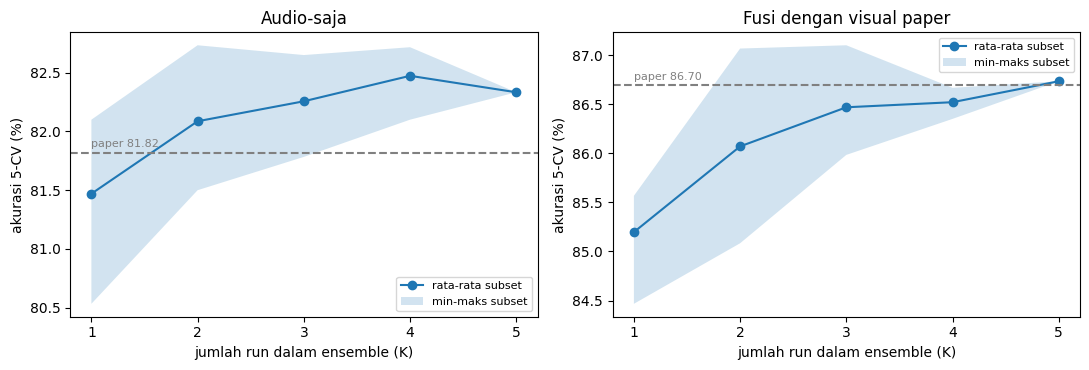

In [9]:
if ENS_OK:
    # per run (diagnostik) + kurva ukuran ensemble (rata-rata semua subset berukuran K)
    rows = []
    for lab, d, z in zip(RUN_LABELS, RUN_DIRS, RUN_Z):
        aa = [float((z[f]["logits_test"].argmax(1) == z[f]["y_test"]).mean() * 100) for f in range(5)]
        ff = u.fusion_cv(REPO_DIR, branches=("audio_e5", "bilstm", "mlp"), modify=wf.make_audio_modify(d))["acc"]
        rows.append({"Run": lab, "Audio": np.mean(aa), "Fusi": np.mean(ff), "Audio per fold": [round(a, 1) for a in aa], "Fusi per fold": [round(a, 1) for a in ff]})
    ENS_RUN_TABLE = pd.DataFrame(rows); display(ENS_RUN_TABLE.round(2)); ENS_RUN_TABLE.round(2).to_csv("results/w3_ensemble_per_run.csv", index=False)
    idx = list(range(ENS_K)); curve = []
    for k in range(1, ENS_K + 1):
        subs = list(itertools.combinations(idx, k)) if ENS_K <= 5 else [tuple(range(k))]
        a_, f_ = [], []
        for s_ in subs:
            zs = [RUN_Z[i] for i in s_]
            a_.append(np.mean([accuracy_score(t, p) * 100 for t, p in zip(*ens_audio_lists(zs))]))
            f_.append(np.mean(u.fusion_cv(REPO_DIR, branches=("audio_e5", "bilstm", "mlp"), modify=make_ens_modify(zs))["acc"]))
        curve.append({"K run": k, "jumlah subset": len(subs), "Audio rata-rata": np.mean(a_), "Audio min": np.min(a_), "Audio maks": np.max(a_),
                      "Fusi rata-rata": np.mean(f_), "Fusi min": np.min(f_), "Fusi maks": np.max(f_)})
    CURVE = pd.DataFrame(curve); display(CURVE.round(2)); CURVE.round(2).to_csv("results/w3_ensemble_ukuran.csv", index=False)
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
    for ax, col, ref, ttl in ((axs[0], "Audio", 81.82, "Audio-saja"), (axs[1], "Fusi", 86.70, "Fusi dengan visual paper")):
        ax.plot(CURVE["K run"], CURVE[f"{col} rata-rata"], "o-", label="rata-rata subset"); ax.fill_between(CURVE["K run"], CURVE[f"{col} min"], CURVE[f"{col} maks"], alpha=.2, label="min-maks subset")
        ax.axhline(ref, ls="--", color="gray"); ax.text(1, ref + 0.05, f"paper {ref:.2f}", fontsize=8, color="gray")
        ax.set_xticks(CURVE["K run"]); ax.set_xlabel("jumlah run dalam ensemble (K)"); ax.set_ylabel("akurasi 5-CV (%)"); ax.set_title(ttl); ax.legend(fontsize=8)
    plt.tight_layout(); plt.savefig("results/w3_ensemble_kurva_ukuran.png", dpi=150); plt.show()

## 2. Tabel hasil lintas metode dan lintas fold

In [10]:
def ci_(accs, n): return 1.96 * np.sqrt(np.mean(accs) / 100 * (1 - np.mean(accs) / 100) / n) * 100
rows = []
for nm, v in S.items():
    f1m = float(np.mean(v["f1"])) if v["f1"] is not None else v.get("f1_mean")
    rows.append({"Keluarga": v["family"], "Metode": nm, "Fold 0": v["acc"][0], "Fold 1": v["acc"][1], "Fold 2": v["acc"][2], "Fold 3": v["acc"][3], "Fold 4": v["acc"][4],
                 "Akurasi rata-rata": float(np.mean(v["acc"])), "Std fold": float(np.std(v["acc"], ddof=1)), "±CI95 (binomial)": ci_(v["acc"], v["n"]), "F1-macro": f1m, "Sumber": v["source"]})
TAB = pd.DataFrame(rows).sort_values(["Keluarga", "Akurasi rata-rata"], ascending=[True, False]).reset_index(drop=True)
TAB.round(2).to_csv("results/w3_tabel_lintas_fold.csv", index=False)
TAB.round(2)

,Keluarga,Metode,Fold 0,Fold 1,Fold 2,Fold 3,Fold 4,Akurasi rata-rata,Std fold,±CI95 (binomial),F1-macro,Sumber
0,audio,E5 audio ensemble,83.67,82.67,81.33,80.67,83.33,82.33,1.29,1.97,81.53,rata-rata logit 5 run E5
1,audio,"E5 audio (epoch terakhir, R4)",83.67,83.33,81.00,81.67,80.83,82.10,1.32,1.98,81.70,logit E5 R4
2,audio,Paper audio FT-Wav2Vec2,85.67,83.00,79.00,82.67,78.75,81.82,2.93,1.99,81.27,posterior rilisan paper
3,audio,E3b: fitur kaya + SVC tuning CV-dalam,55.00,51.30,52.70,51.70,54.60,53.06,1.67,2.58,51.71,dibaca dari output R4
4,audio,E3: MFCC + SVC RBF C=10,53.70,54.00,51.30,49.70,46.70,51.08,3.02,2.58,49.61,dibaca dari output R4
5,audio,E3: MFCC + RandomForest-500,50.70,47.00,43.30,56.70,42.50,48.04,5.84,2.58,44.22,dibaca dari output R4
6,audio_FE,Paper audio FE: MLP80 (emb 512-d),60.00,57.33,56.33,55.67,53.33,56.53,2.43,2.56,55.93,dihitung ulang
7,audio_FE,Paper audio FE: SVC C=10 (emb 512-d),62.00,53.33,51.00,49.67,49.58,53.12,5.19,2.58,52.29,dihitung ulang
8,fusion,E2c: + AU out-of-fold (SVC) sbg cabang ke-4,88.67,89.00,85.33,86.00,85.83,86.97,1.73,1.74,86.75,dihitung ulang
9,fusion,E5 fusi ensemble (audio ens + visual paper),88.33,89.00,86.33,83.33,86.67,86.73,2.20,1.75,86.31,rata-rata logit 5 run E5


## 3. Uji signifikansi sederhana: paired t-test antar fold
Metrik utama: **akurasi per fold** (5 pasangan, fold yang sama). Perbandingan **direncanakan di muka**: tiap metode pembanding vs padanan sepadan di paper — audio vs audio paper, audio klasik vs embedding paper (FE), visual vs visual paper, fusi vs fusi paper. E4 (song) dan epoch-terbaik-pada-fold-uji **tidak** diuji karena tidak sebanding/optimistis. Bila run E5 tambahan tersedia, **ensemble E5** (audio vs audio paper; fusi dan fusi + AU out-of-fold vs fusi paper) ikut direncanakan di muka dan masuk koreksi Holm.

In [11]:
def paired(c, r):
    c, r = np.array(c, float), np.array(r, float); d = c - r; n = len(d); sd = d.std(ddof=1); se = sd / np.sqrt(n)
    t, p = stats.ttest_rel(c, r) if sd > 0 else (np.nan, 1.0); h = stats.t.ppf(0.975, n - 1) * se
    return dict(delta=d.mean(), ci_lo=d.mean() - h, ci_hi=d.mean() + h, t=t, p=p, dz=(d.mean() / sd) if sd > 0 else np.nan, wins=int((d > 0).sum()))
PLAN = [  # (keluarga, kandidat, referensi)
 ("Audio-saja", "E5 audio (epoch terakhir, R4)", "Paper audio FT-Wav2Vec2"),
 ("Audio-saja", "E3: MFCC + SVC RBF C=10", "Paper audio FT-Wav2Vec2"),
 ("Audio-saja", "E3b: fitur kaya + SVC tuning CV-dalam", "Paper audio FT-Wav2Vec2"),
 ("Audio klasik vs FE paper", "E3: MFCC + SVC RBF C=10", "Paper audio FE: SVC C=10 (emb 512-d)"),
 ("Audio klasik vs FE paper", "E3b: fitur kaya + SVC tuning CV-dalam", "Paper audio FE: SVC C=10 (emb 512-d)"),
 ("Audio klasik vs FE paper", "E3b: fitur kaya + SVC tuning CV-dalam", "Paper audio FE: MLP80 (emb 512-d)"),
 ("Visual", "E1: SVC C=1 balanced (AU)", "Paper visual statis: MLP80 (AU rata-rata)"),
 ("Visual", "E1: SVC C=1 balanced (AU)", "Paper visual bi-LSTM"),
 ("Visual", "E1: ExtraTrees-500 balanced (AU)", "Paper visual statis: MLP80 (AU rata-rata)"),
 ("Fusi", "E5 fusi (audio E5 + visual paper)", "Fusi baseline (replikasi 86,70)"),
 ("Fusi", "E5 fusi + AU out-of-fold", "Fusi baseline (replikasi 86,70)"),
 ("Fusi", "E2a: LogReg balanced", "Fusi baseline (replikasi 86,70)"),
 ("Fusi", "E2a: LogReg C=10", "Fusi baseline (replikasi 86,70)"),
 ("Fusi", "E2a: SVC RBF", "Fusi baseline (replikasi 86,70)"),
 ("Fusi", "E2a: RandomForest-300", "Fusi baseline (replikasi 86,70)"),
 ("Fusi", "E2c: + AU out-of-fold (SVC) sbg cabang ke-4", "Fusi baseline (replikasi 86,70)"),
]
if ENS_OK:                                                                  # ensemble E5 (bagian 1b): 3 perbandingan tambahan, ikut koreksi Holm
    PLAN += [("Audio-saja", "E5 audio ensemble", "Paper audio FT-Wav2Vec2"),
             ("Fusi", "E5 fusi ensemble (audio ens + visual paper)", "Fusi baseline (replikasi 86,70)"),
             ("Fusi", "E5 fusi ensemble + AU out-of-fold", "Fusi baseline (replikasi 86,70)")]
res = [dict(Keluarga=f, Kandidat=c, Referensi=r, **paired(S[c]["acc"], S[r]["acc"])) for f, c, r in PLAN]
T = pd.DataFrame(res)
m = len(T); order = np.argsort(T["p"].values); adj = np.empty(m); run = 0.0               # koreksi Holm (seluruh perbandingan)
for rank, i in enumerate(order):
    run = max(run, (m - rank) * T["p"].values[i]); adj[i] = min(1.0, run)
T["p Holm"] = adj
def verdict(r):
    if r["p Holm"] < 0.05 and (r["ci_lo"] > 0 or r["ci_hi"] < 0): return "signifikan " + ("lebih baik" if r["delta"] > 0 else "lebih buruk")
    return "tidak signifikan"
T["Kesimpulan"] = T.apply(verdict, axis=1)
T_show = T.rename(columns={"delta": "Δ rata-rata (poin)", "ci_lo": "CI95 bawah", "ci_hi": "CI95 atas", "t": "t", "p": "p (mentah)", "dz": "Cohen dz", "wins": "fold lebih baik (dari 5)"})
T_show.round(3).to_csv("results/w3_uji_berpasangan.csv", index=False)
T_show.round(3)

,Keluarga,Kandidat,Referensi,Δ rata-rata (poin),CI95 bawah,CI95 atas,t,p (mentah),Cohen dz,fold lebih baik (dari 5),p Holm,Kesimpulan
0,Audio-saja,"E5 audio (epoch terakhir, R4)",Paper audio FT-Wav2Vec2,0.283,-1.959,2.526,0.351,0.743,0.157,3,1.000,tidak signifikan
1,Audio-saja,E3: MFCC + SVC RBF C=10,Paper audio FT-Wav2Vec2,-30.737,-33.544,-27.929,-30.398,0.000,-13.594,0,0.000,signifikan lebih buruk
2,Audio-saja,E3b: fitur kaya + SVC tuning CV-dalam,Paper audio FT-Wav2Vec2,-28.757,-32.896,-24.617,-19.289,0.000,-8.626,0,0.001,signifikan lebih buruk
3,Audio klasik vs FE paper,E3: MFCC + SVC RBF C=10,Paper audio FE: SVC C=10 (emb 512-d),-2.037,-6.724,2.650,-1.206,0.294,-0.540,3,1.000,tidak signifikan
4,Audio klasik vs FE paper,E3b: fitur kaya + SVC tuning CV-dalam,Paper audio FE: SVC C=10 (emb 512-d),-0.057,-5.791,5.678,-0.027,0.979,-0.012,3,1.000,tidak signifikan
5,Audio klasik vs FE paper,E3b: fitur kaya + SVC tuning CV-dalam,Paper audio FE: MLP80 (emb 512-d),-3.473,-6.964,0.018,-2.762,0.051,-1.235,1,0.761,tidak signifikan
6,Visual,E1: SVC C=1 balanced (AU),Paper visual statis: MLP80 (AU rata-rata),-1.233,-7.104,4.637,-0.583,0.591,-0.261,3,1.000,tidak signifikan
7,Visual,E1: SVC C=1 balanced (AU),Paper visual bi-LSTM,-3.150,-7.016,0.716,-2.262,0.086,-1.012,0,1.000,tidak signifikan
8,Visual,E1: ExtraTrees-500 balanced (AU),Paper visual statis: MLP80 (AU rata-rata),-1.083,-7.801,5.634,-0.448,0.678,-0.200,1,1.000,tidak signifikan
9,Fusi,E5 fusi (audio E5 + visual paper),"Fusi baseline (replikasi 86,70)",-1.133,-2.952,0.685,-1.731,0.159,-0.774,1,1.000,tidak signifikan


**Cara membaca:** CI selisih yang melewati 0 berarti arah perbedaan tidak pasti. Dengan 5 fold, p-value minimum t-test berpasangan memang bisa kecil, tetapi asumsinya (selisih berdistribusi normal, fold independen) rapuh karena fold berbagi aktor-pola yang mirip dan data latih saling tumpang tindih. Perlakukan hasil sebagai **indikasi**, bukan bukti kuat.

## 4. Variabilitas antar-run E5 (resep yang sama)

In [12]:
RUNS = pd.DataFrame([
  {"Run": "Run 1 (history_E5.csv)", "Audio (epoch terakhir)": 81.45, "Fusi": np.nan, "Fusi + AU OOF": np.nan, "Sumber": "history_E5.csv (tanpa tabel fusi)"},
  {"Run": "Run 2 (notebook r3)", "Audio (epoch terakhir)": 82.38, "Fusi": 86.18, "Fusi + AU OOF": 86.35, "Sumber": "output notebook r3"},
  {"Run": "Run 3 (R4, data di notebook ini)", "Audio (epoch terakhir)": float(np.mean(S["E5 audio (epoch terakhir, R4)"]["acc"])),
   "Fusi": float(np.mean(S["E5 fusi (audio E5 + visual paper)"]["acc"])), "Fusi + AU OOF": float(np.mean(S["E5 fusi + AU out-of-fold"]["acc"])), "Sumber": "npz R4 (dihitung ulang)"}])
if ENS_OK:                                                       # run tambahan (seed berbeda) dari bagian 1b, selain R4
    extra = [{"Run": f"Run tambahan: {r.Run}", "Audio (epoch terakhir)": r.Audio, "Fusi": r.Fusi, "Fusi + AU OOF": np.nan, "Sumber": "npz run tambahan"} for r in ENS_RUN_TABLE.iloc[1:].itertuples()]
    RUNS = pd.concat([RUNS, pd.DataFrame(extra)], ignore_index=True)
summ = RUNS[["Audio (epoch terakhir)", "Fusi", "Fusi + AU OOF"]].agg(["mean", "std", "min", "max"]).round(2)
summ.loc["paper"] = [81.82, 86.70, 86.70]
display(RUNS.round(2)); display(summ)
if ENS_OK:
    ens_row = pd.DataFrame([{"Sistem": f"Ensemble {ENS_K} run (rata-rata logit)", "Audio": np.mean(S["E5 audio ensemble"]["acc"]),
                             "Fusi": np.mean(S["E5 fusi ensemble (audio ens + visual paper)"]["acc"]), "Fusi + AU OOF": np.mean(S["E5 fusi ensemble + AU out-of-fold"]["acc"])}])
    display(ens_row.round(2))
RUNS.round(2).to_csv("results/w3_variabilitas_E5.csv", index=False)

,Run,Audio (epoch terakhir),Fusi,Fusi + AU OOF,Sumber
0,Run 1 (history_E5.csv),81.45,NaN,NaN,history_E5.csv (tanpa tabel fusi)
1,Run 2 (notebook r3),82.38,86.18,86.35,output notebook r3
2,"Run 3 (R4, data di notebook ini)",82.10,85.57,85.45,npz R4 (dihitung ulang)
3,Run tambahan: ../input/datasets/jesayash/10000...,81.38,85.53,NaN,npz run tambahan
4,Run tambahan: ../input/datasets/jesayash/8000-...,80.53,84.47,NaN,npz run tambahan
5,Run tambahan: ../input/datasets/jesayash/hasil...,81.95,85.27,NaN,npz run tambahan
6,Run tambahan: ../input/datasets/jesayash/hasil...,81.38,85.15,NaN,npz run tambahan


,Audio (epoch terakhir),Fusi,Fusi + AU OOF
mean,81.60,85.36,85.90
std,0.61,0.56,0.64
min,80.53,84.47,85.45
max,82.38,86.18,86.35
paper,81.82,86.70,86.70


,Sistem,Audio,Fusi,Fusi + AU OOF
0,Ensemble 5 run (rata-rata logit),82.33,86.73,86.55


## 5. Confusion matrix (agregat 5 fold): baseline vs E5

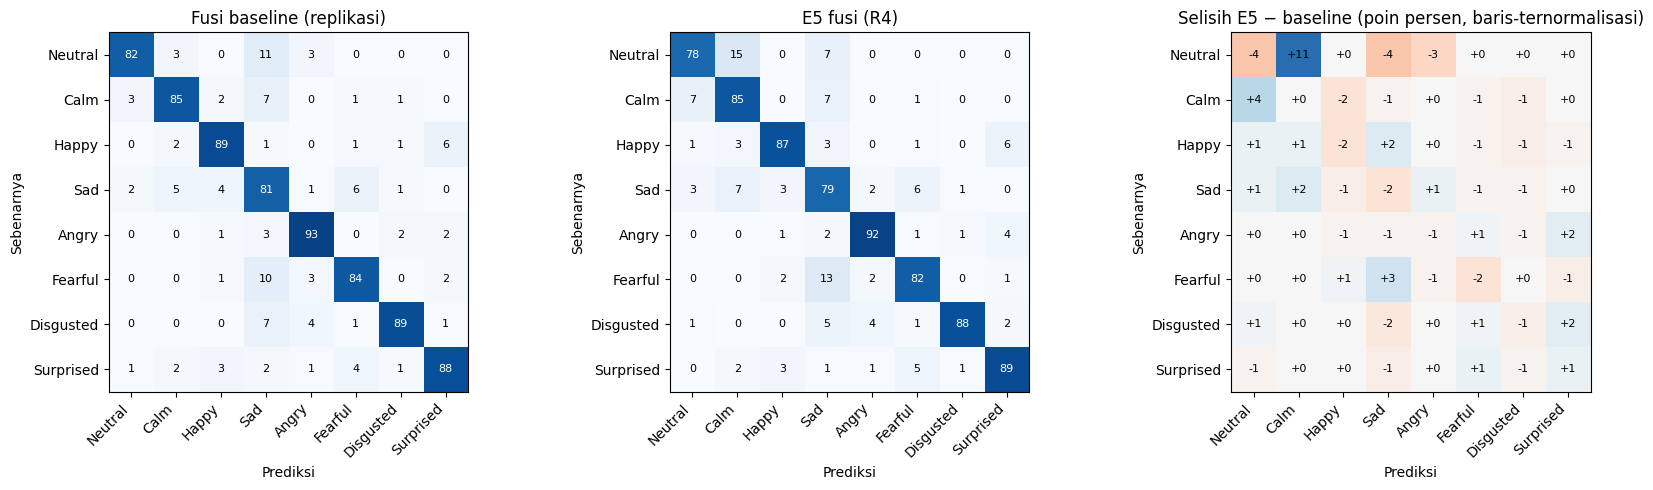

Kesalahan terbanyak E5 fusi (jumlah rekaman, benar -> prediksi): [('Fearful->Sad', 25), ('Neutral->Calm', 14), ('Calm->Neutral', 14), ('Sad->Calm', 13), ('Calm->Sad', 13), ('Sad->Fearful', 11)]


In [13]:
def cm_agg(name):
    v = S[name]; return sum(confusion_matrix(t, p, labels=range(8)) for t, p in zip(v["yt"], v["yp"]))
CM = {k: cm_agg(k) for k in ("Fusi baseline (replikasi 86,70)", "E5 fusi (audio E5 + visual paper)", "Paper audio FT-Wav2Vec2", "E5 audio (epoch terakhir, R4)")}
norm = lambda M: M / M.sum(1, keepdims=True) * 100
fig, axs = plt.subplots(1, 3, figsize=(17, 5))
for ax, (title, M) in zip(axs[:2], [("Fusi baseline (replikasi)", CM["Fusi baseline (replikasi 86,70)"]), ("E5 fusi (R4)", CM["E5 fusi (audio E5 + visual paper)"])]):
    im = ax.imshow(norm(M), cmap="Blues", vmin=0, vmax=100); ax.set_title(title)
    for i in range(8):
        for j in range(8): ax.text(j, i, f"{norm(M)[i, j]:.0f}", ha="center", va="center", fontsize=8, color="white" if norm(M)[i, j] > 50 else "black")
D = norm(CM["E5 fusi (audio E5 + visual paper)"]) - norm(CM["Fusi baseline (replikasi 86,70)"])
axs[2].imshow(D, cmap="RdBu", vmin=-15, vmax=15); axs[2].set_title("Selisih E5 − baseline (poin persen, baris-ternormalisasi)")
for i in range(8):
    for j in range(8): axs[2].text(j, i, f"{D[i, j]:+.0f}", ha="center", va="center", fontsize=8)
for ax in axs:
    ax.set_xticks(range(8)); ax.set_yticks(range(8)); ax.set_xticklabels(CLASSES, rotation=45, ha="right"); ax.set_yticklabels(CLASSES); ax.set_xlabel("Prediksi"); ax.set_ylabel("Sebenarnya")
plt.tight_layout(); plt.savefig("results/w3_confusion_matrix.png", dpi=150); plt.show()
# kesalahan terbesar (di luar diagonal) pada E5 fusi
M = CM["E5 fusi (audio E5 + visual paper)"].copy(); np.fill_diagonal(M, 0)
top = sorted([(M[i, j], CLASSES[i], CLASSES[j]) for i in range(8) for j in range(8) if M[i, j] > 0], reverse=True)[:6]
print("Kesalahan terbanyak E5 fusi (jumlah rekaman, benar -> prediksi):", [(f"{a}->{b}", int(n)) for n, a, b in top])

## 6. Boxplot skor per kelas (recall per fold)

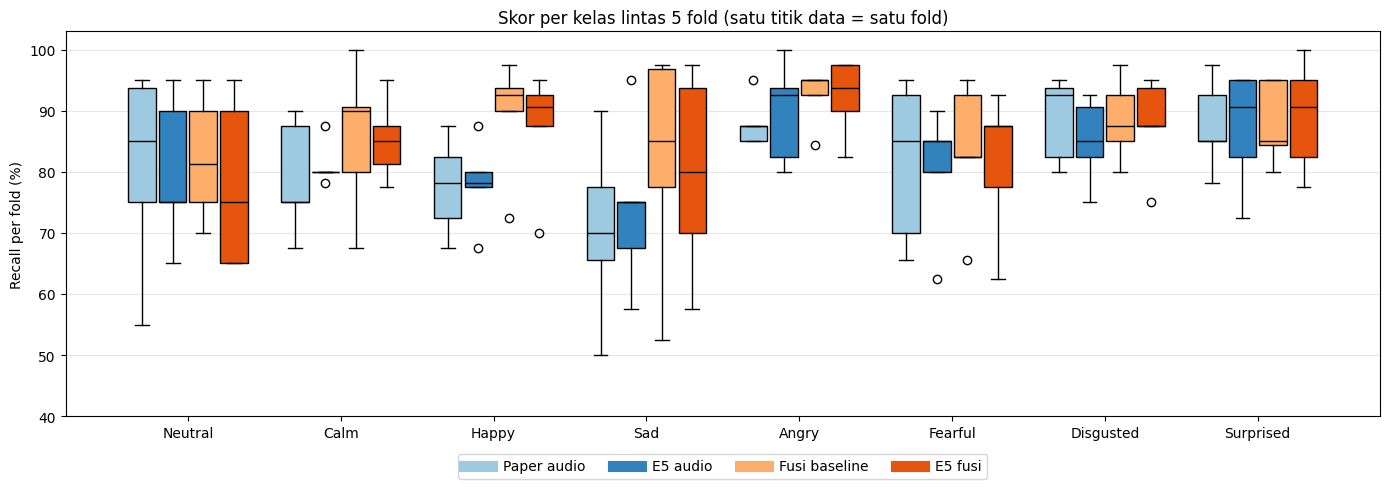

,Paper audio,E5 audio,Fusi baseline,E5 fusi,Δ E5 fusi − baseline,Δ E5 audio − paper audio
Neutral,80.8,80.0,82.2,78.0,-4.2,-0.8
Calm,79.0,81.1,85.6,85.2,-0.4,2.1
Happy,77.6,78.1,89.2,87.1,-2.1,0.5
Sad,70.6,74.0,81.9,79.8,-2.1,3.4
Angry,88.0,89.8,92.4,92.2,-0.2,1.8
Fearful,81.6,80.5,83.6,81.5,-2.1,-1.1
Disgusted,88.8,85.1,88.5,87.8,-0.7,-3.7
Surprised,87.6,87.1,87.9,89.1,1.2,-0.5


In [14]:
METH = ["Paper audio FT-Wav2Vec2", "E5 audio (epoch terakhir, R4)", "Fusi baseline (replikasi 86,70)", "E5 fusi (audio E5 + visual paper)"]
COL = ["#9ecae1", "#3182bd", "#fdae6b", "#e6550d"]; LAB = ["Paper audio", "E5 audio", "Fusi baseline", "E5 fusi"]
fig, ax = plt.subplots(figsize=(14, 5)); w = 0.2
for k, (mname, c, lb) in enumerate(zip(METH, COL, LAB)):
    bp = ax.boxplot([S[mname]["rec"][:, ci] for ci in range(8)], positions=np.arange(8) + (k - 1.5) * w, widths=w * 0.9, patch_artist=True, showfliers=True)
    for b in bp["boxes"]: b.set_facecolor(c)
    for md_ in bp["medians"]: md_.set_color("black")
    ax.plot([], [], color=c, lw=8, label=lb)
ax.set_xticks(range(8)); ax.set_xticklabels(CLASSES); ax.set_ylabel("Recall per fold (%)"); ax.set_title("Skor per kelas lintas 5 fold (satu titik data = satu fold)")
ax.set_ylim(40, 103); ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08)); ax.grid(axis="y", alpha=.3); plt.tight_layout(); plt.savefig("results/w3_boxplot_per_kelas.png", dpi=150); plt.show()
PC = pd.DataFrame({lb: S[mn]["rec"].mean(0) for mn, lb in zip(METH, LAB)}, index=CLASSES).round(1)
PC["Δ E5 fusi − baseline"] = (PC["E5 fusi"] - PC["Fusi baseline"]).round(1); PC["Δ E5 audio − paper audio"] = (PC["E5 audio"] - PC["Paper audio"]).round(1)
PC.to_csv("results/w3_recall_per_kelas.csv"); PC

**Catatan:** *neutral* hanya ±19 rekaman uji per fold (setengah kelas lain), sehingga recall-nya sangat bergantung pada satu-dua rekaman dan boxplot-nya lebar. Jangan menafsirkan selisih satu kelas sebagai perbedaan metode tanpa melihat sebaran antar-fold.

## 7. Kurva validasi E5 (riwayat latih R4)

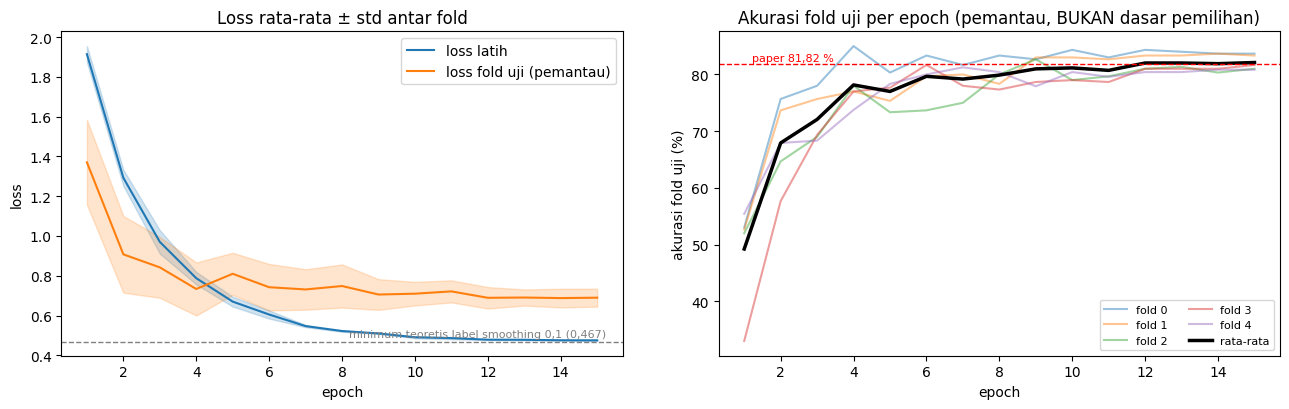

Epoch terakhir: akurasi 82.10 % (std fold 1.32); loss latih 0.475
Epoch 10-15: akurasi uji bergerak di 80.7-82.1 % -> plateau; menambah epoch tidak membantu.


In [15]:
H = pd.read_csv(HIST)
g = H.groupby("epoch")[["train_loss", "test_loss", "test_acc"]].agg(["mean", "std"])
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for col, lb, c in (("train_loss", "loss latih", "#1f77b4"), ("test_loss", "loss fold uji (pemantau)", "#ff7f0e")):
    axs[0].plot(g.index, g[(col, "mean")], label=lb, color=c); axs[0].fill_between(g.index, g[(col, "mean")] - g[(col, "std")], g[(col, "mean")] + g[(col, "std")], alpha=.2, color=c)
axs[0].axhline(0.467, ls="--", color="gray", lw=1); axs[0].text(8.2, 0.49, "minimum teoretis label smoothing 0,1 (0,467)", fontsize=8, color="gray")
axs[0].set_xlabel("epoch"); axs[0].set_ylabel("loss"); axs[0].legend(); axs[0].set_title("Loss rata-rata ± std antar fold")
for f, d in H.groupby("fold"): axs[1].plot(d["epoch"], d["test_acc"], alpha=.45, label=f"fold {int(f)}")
axs[1].plot(g.index, g[("test_acc", "mean")], color="black", lw=2.5, label="rata-rata"); axs[1].axhline(81.82, ls="--", color="red", lw=1); axs[1].text(1.2, 82.3, "paper 81,82 %", color="red", fontsize=8)
axs[1].set_xlabel("epoch"); axs[1].set_ylabel("akurasi fold uji (%)"); axs[1].legend(ncol=2, fontsize=8); axs[1].set_title("Akurasi fold uji per epoch (pemantau, BUKAN dasar pemilihan)")
plt.tight_layout(); plt.savefig("results/w3_kurva_validasi_E5.png", dpi=150); plt.show()
last = H[H.epoch == H.epoch.max()]; print(f"Epoch terakhir: akurasi {last.test_acc.mean():.2f} % (std fold {last.test_acc.std():.2f}); loss latih {last.train_loss.mean():.3f}")
plateau = g[("test_acc", "mean")].iloc[9:]; print(f"Epoch 10-{int(g.index.max())}: akurasi uji bergerak di {plateau.min():.1f}-{plateau.max():.1f} % -> plateau; menambah epoch tidak membantu.")

## 8. Ringkasan otomatis (dibangkitkan dari angka di atas)

In [16]:
def line(c, r):
    row = T[(T.Kandidat == c) & (T.Referensi == r)].iloc[0]
    return (f"- **{c}** vs **{r}**: Δ = {row.delta:+.2f} poin (CI95 {row.ci_lo:+.2f} s.d. {row.ci_hi:+.2f}), lebih baik di {int(row.wins)}/5 fold, "
            f"p mentah = {row.p:.3f}, p Holm = {row['p Holm']:.3f} → **{row.Kesimpulan}**.")
from IPython.display import Markdown
txt = "### Temuan utama\n" + "\n".join([
    line("E5 audio (epoch terakhir, R4)", "Paper audio FT-Wav2Vec2"),
    line("E5 fusi (audio E5 + visual paper)", "Fusi baseline (replikasi 86,70)"),
    line("E5 fusi + AU out-of-fold", "Fusi baseline (replikasi 86,70)"),
    line("E3b: fitur kaya + SVC tuning CV-dalam", "Paper audio FE: SVC C=10 (emb 512-d)"),
    line("E1: SVC C=1 balanced (AU)", "Paper visual statis: MLP80 (AU rata-rata)")]
    + ([line("E5 audio ensemble", "Paper audio FT-Wav2Vec2"), line("E5 fusi ensemble (audio ens + visual paper)", "Fusi baseline (replikasi 86,70)"),
        line("E5 fusi ensemble + AU out-of-fold", "Fusi baseline (replikasi 86,70)")] if ENS_OK else []))
sig = T[T.Kesimpulan != "tidak signifikan"]
txt += "\n\n**Perbandingan yang signifikan setelah koreksi Holm:** " + (", ".join(f"{r.Kandidat} vs {r.Referensi} ({r.Kesimpulan})" for r in sig.itertuples()) if len(sig) else "tidak ada.")
better = T[T.Kesimpulan == "signifikan lebih baik"]
if len(better):
    txt += "\n\n**Di atas paper?** Ya untuk: " + ", ".join(f"{r.Kandidat} vs {r.Referensi}" for r in better.itertuples()) + " (signifikan setelah koreksi Holm)."
else:
    txt += ("\n\n**Di atas paper?** Pada protokol yang sama, tidak ada metode pembanding yang terbukti lebih baik dari padanannya di paper setelah koreksi. "
            "Audio E5 setara (selisih jauh di bawah variabilitas antar-run ≈ 1 poin); fusi E5 satu run cenderung sedikit lebih rendah; fitur klasik jauh di bawah model pra-latih.")
if ENS_OK:
    ens3 = [("audio", "E5 audio ensemble", 81.82), ("fusi", "E5 fusi ensemble (audio ens + visual paper)", 86.70), ("fusi + AU out-of-fold", "E5 fusi ensemble + AU out-of-fold", 86.70)]
    parts = [f"{lab} {np.mean(S[k]['acc']):.2f} % (paper {ref:.2f}; {np.mean(S[k]['acc']) - ref:+.2f})" for lab, k, ref in ens3]
    n_above = sum(np.mean(S[k]["acc"]) > ref for _, k, ref in ens3)
    txt += (f"\n\n**Ensemble {ENS_K} run E5:** " + "; ".join(parts) + ". "
            + (f"Rata-rata {n_above} dari 3 sistem ensemble berada di atas angka paper, tetapi selisih sekecil itu sebanding dengan derau antar-fold dan antar-run; baca CI dan p Holm di atas, bukan hanya angka rata-rata."
               if n_above else "Tidak ada sistem ensemble yang rata-ratanya melewati angka paper."))
Markdown(txt)

### Temuan utama
- **E5 audio (epoch terakhir, R4)** vs **Paper audio FT-Wav2Vec2**: Δ = +0.28 poin (CI95 -1.96 s.d. +2.53), lebih baik di 3/5 fold, p mentah = 0.743, p Holm = 1.000 → **tidak signifikan**.
- **E5 fusi (audio E5 + visual paper)** vs **Fusi baseline (replikasi 86,70)**: Δ = -1.13 poin (CI95 -2.95 s.d. +0.68), lebih baik di 1/5 fold, p mentah = 0.159, p Holm = 1.000 → **tidak signifikan**.
- **E5 fusi + AU out-of-fold** vs **Fusi baseline (replikasi 86,70)**: Δ = -1.25 poin (CI95 -3.78 s.d. +1.28), lebih baik di 2/5 fold, p mentah = 0.242, p Holm = 1.000 → **tidak signifikan**.
- **E3b: fitur kaya + SVC tuning CV-dalam** vs **Paper audio FE: SVC C=10 (emb 512-d)**: Δ = -0.06 poin (CI95 -5.79 s.d. +5.68), lebih baik di 3/5 fold, p mentah = 0.979, p Holm = 1.000 → **tidak signifikan**.
- **E1: SVC C=1 balanced (AU)** vs **Paper visual statis: MLP80 (AU rata-rata)**: Δ = -1.23 poin (CI95 -7.10 s.d. +4.64), lebih baik di 3/5 fold, p mentah = 0.591, p Holm = 1.000 → **tidak signifikan**.
- **E5 audio ensemble** vs **Paper audio FT-Wav2Vec2**: Δ = +0.52 poin (CI95 -3.06 s.d. +4.10), lebih baik di 2/5 fold, p mentah = 0.709, p Holm = 1.000 → **tidak signifikan**.
- **E5 fusi ensemble (audio ens + visual paper)** vs **Fusi baseline (replikasi 86,70)**: Δ = +0.03 poin (CI95 -1.84 s.d. +1.91), lebih baik di 3/5 fold, p mentah = 0.963, p Holm = 1.000 → **tidak signifikan**.
- **E5 fusi ensemble + AU out-of-fold** vs **Fusi baseline (replikasi 86,70)**: Δ = -0.15 poin (CI95 -2.19 s.d. +1.89), lebih baik di 2/5 fold, p mentah = 0.848, p Holm = 1.000 → **tidak signifikan**.

**Perbandingan yang signifikan setelah koreksi Holm:** E3: MFCC + SVC RBF C=10 vs Paper audio FT-Wav2Vec2 (signifikan lebih buruk), E3b: fitur kaya + SVC tuning CV-dalam vs Paper audio FT-Wav2Vec2 (signifikan lebih buruk)

**Di atas paper?** Pada protokol yang sama, tidak ada metode pembanding yang terbukti lebih baik dari padanannya di paper setelah koreksi. Audio E5 setara (selisih jauh di bawah variabilitas antar-run ≈ 1 poin); fusi E5 satu run cenderung sedikit lebih rendah; fitur klasik jauh di bawah model pra-latih.

**Ensemble 5 run E5:** audio 82.33 % (paper 81.82; +0.51); fusi 86.73 % (paper 86.70; +0.03); fusi + AU out-of-fold 86.55 % (paper 86.70; -0.15). Rata-rata 2 dari 3 sistem ensemble berada di atas angka paper, tetapi selisih sekecil itu sebanding dengan derau antar-fold dan antar-run; baca CI dan p Holm di atas, bukan hanya angka rata-rata.

## 9. Keterbatasan (untuk laporan)
- **n = 5 fold:** daya uji rendah; p-value dan CI rapuh. Fold juga tidak benar-benar independen (data latih tumpang tindih).
- **Angka paper optimistis:** di kode penulis checkpoint audio dan early-stopping bi-LSTM dipilih memakai fold uji. Cabang visual pada fusi E5 memakai posterior paper (juga terpilih dengan fold uji), sedangkan audio E5 tidak → asimetri yang dapat menjelaskan sebagian selisih fusi (dugaan, belum terbukti; saturasi logit dan komplementaritas kesalahan sudah diperiksa dan **tidak** menjelaskannya).
- **Variabilitas antar-run:** resep E5 yang sama memberi 81,45–82,38 % (audio) dan 85,57–86,18 % (fusi) pada run berbeda (GPU tidak deterministik).
- **E3/E3b/E4:** hanya akurasi per fold (dibulatkan 0,1) yang tersedia dari output notebook; F1 per fold dan confusion matrix-nya tidak dihitung ulang. E4 memakai kanal **song** sehingga tidak sebanding dengan paper.
- Kepala fusi dilatih pada posterior data latih *in-sample*; pemilihan kandidat dari CV yang sama membawa sedikit bias seleksi.
- Normalisasi per-aktor sengaja tidak dipakai (transduktif, tidak dipakai paper).
- **Ensemble E5 (bila dipakai):** hanya mengurangi derau antar-run pada cabang audio. Ia tidak menghilangkan asimetri seleksi dengan cabang visual paper, tidak menambah informasi baru, dan jumlah run kecil (K ≈ 3) membuat estimasinya tetap kasar. Laporkan semua run yang dipakai dan seed-nya.

In [17]:
print("Berkas keluaran di results/:", sorted(f for f in os.listdir("results") if f.startswith("w3_")))

Berkas keluaran di results/: ['w3_boxplot_per_kelas.png', 'w3_confusion_matrix.png', 'w3_ensemble_kurva_ukuran.png', 'w3_ensemble_per_run.csv', 'w3_ensemble_ukuran.csv', 'w3_kurva_validasi_E5.png', 'w3_recall_per_kelas.csv', 'w3_tabel_lintas_fold.csv', 'w3_uji_berpasangan.csv', 'w3_variabilitas_E5.csv']
